# Inference

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Apply the detector to new imagery and learn from the predictions it gets wrong
</div>
<!-- markdownlint-enable MD033 -->

---

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HendrikWulf/sds320-jb/blob/main/book/04_lessons/L06/07_inference-and-visualisation.ipynb)

---

## 1. Motivation

A model's evaluation metrics summarize performance across an entire held-out set. Running {term}`inference <Inference>` on individual images and looking at the results directly is what tells you *how* the model fails, not just how often, which matters when you need to decide whether a detector is good enough for a specific project deliverable.

---

## 2. Core idea

`geoai`'s inference functions handle three things for you automatically: tiling a large input image into overlapping windows so it fits the model, running each window through the model, and applying {term}`non-maximum suppression <Non-Maximum Suppression>` to merge duplicate detections that appear at tile boundaries. You still choose the confidence threshold, which decides how many of the model's raw predictions actually get reported.

---

## 3. Workflow

On the previous page, quantitative metrics summarized detector performance. Now you will apply the trained model to individual images and inspect what the predictions actually look like. {term}`Inference` is the process of applying a trained model to new input data. For object detection, the result is typically a collection of:

- bounding boxes,
- class labels,
- confidence scores.

Visual inspection is important because metrics alone do not tell you **why** a detector fails.

### A. Prepare the dataset

The following cells reproduce the setup from the previous page so that the key training variables are explicit.

```{admonition} Running on a Mac with Apple silicon
:class: note
On a Mac with an M-series chip, PyTorch uses the GPU through its MPS backend. One operation the detector needs, non-maximum suppression (`torchvision::nms`), is not yet available on MPS, so without the setting below the code stops with a `NotImplementedError`. Setting `PYTORCH_ENABLE_MPS_FALLBACK=1` runs just that operation on the CPU while everything else stays on the GPU. It must be set before PyTorch is imported (here via `geoai`), so if you have already run the imports, restart the kernel first. On Windows, Linux or Google Colab the setting has no effect and you can leave it in place.
```

In [1]:
import os

# Apple silicon only: run operations missing on MPS on the CPU instead
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import json
import geoai
from pathlib import Path

In [2]:
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L06/data/NWPU-VHR-10.zip"

data_dir = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

splits = geoai.prepare_nwpu_vhr10(
    data_dir,
    val_split=0.2,
    seed=42,
)

In [3]:
output_dir = "nwpu_output"

model_path = geoai.train_multiclass_detector(
    images_dir=splits["images_dir"],
    annotations_path=splits["train_annotations"],
    output_dir=output_dir,
    model_name="fasterrcnn_resnet50_fpn_v2",
    class_names=splits["class_names"],
    num_channels=3,
    batch_size=4,
    num_epochs=10,
    learning_rate=0.005,
    val_split=0.1,
    seed=42,
    pretrained=True,
    verbose=True,
)

[W1013 18:47:18.274943000 MPSFallback.mm:34] Warning: The operator 'torchvision::nms' is not currently supported on the MPS backend and will fall back to run on the CPU. This may have performance implications. (function operator())


### B. Run inference on a single image

The validation annotations contain the filenames of images that were held out from the main training split.

In [4]:
with open(splits["val_annotations"], "r") as f:
    val_data = json.load(f)

test_img_info = val_data["images"][0]

test_img_path = os.path.join(
    splits["images_dir"],
    test_img_info["file_name"],
)

print(test_img_path)

data/raw/NWPU-VHR-10/positive_image_set/266.jpg


This cell reactivates a familiar pattern:

1. open a file,
2. load structured JSON,
3. access a dictionary value,
4. construct a path.

The `geoai.multiclass_detection` workflow applies the trained detector to the input image.

In [5]:
output_raster = "nwpu_detection_output.tif"

result_path, inference_time, detections = geoai.multiclass_detection(
    input_path=test_img_path,
    output_path=output_raster,
    model_path=model_path,
    num_classes=splits["num_classes"],
    class_names=splits["class_names"],
    window_size=512,
    overlap=256,
    confidence_threshold=0.5,
    batch_size=4,
    num_channels=3,
)

print(f"Inference time: {inference_time:.2f} s")
print(f"Detections: {len(detections)}")

  0%|          | 0/6 [00:00<?, ?it/s]

Inference time: 5.48 s
Detections: 5


Several parameters deserve attention.

`window_size` and `overlap` control the tiling: a 512-pixel window with 256 pixels of overlap means every part of the image is covered by at least two overlapping windows, which is what makes cross-tile non-maximum suppression necessary in the first place. `confidence_threshold=0.5` filters out lower-certainty predictions before they are returned; this is the same trade-off introduced on the concepts page, and you can adjust it directly here.

### C. Visualize the detections

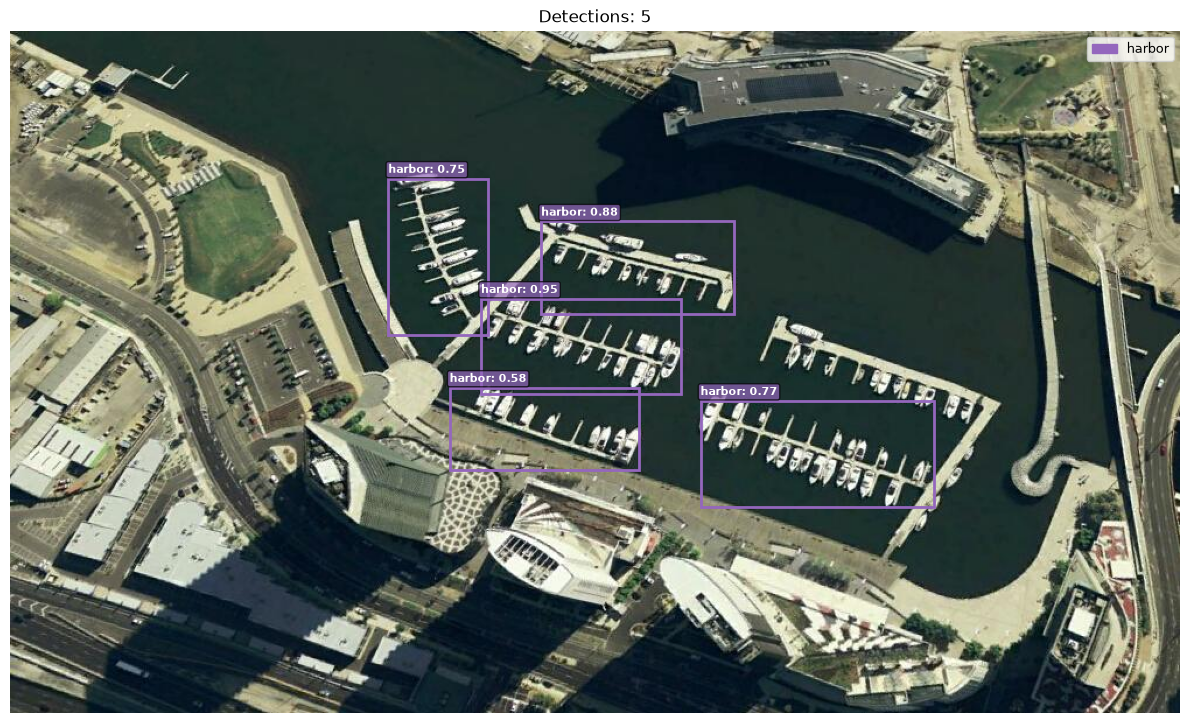

In [9]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap


geoai.visualize_multiclass_detections(
    image_path=test_img_path,
    detections=detections,
    class_names=splits["class_names"],
    confidence_threshold=0.5,
    figsize=(12, 10),
)

This overlays each detected box on the original image, color-coded by class and labeled with the class name and confidence score. Looking at this directly, rather than only at the printed detection count, is how you catch a box that is technically "correct" by IoU but visually nonsensical, or a class label that looks obviously wrong for the object shown.

### D. Batch inference on multiple images

Once one image works, you can process several images using {term}`Batch Inference`.

In [7]:
val_image_paths = [
    os.path.join(
        splits["images_dir"],
        image["file_name"],
    )
    for image in val_data["images"][:4]
]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

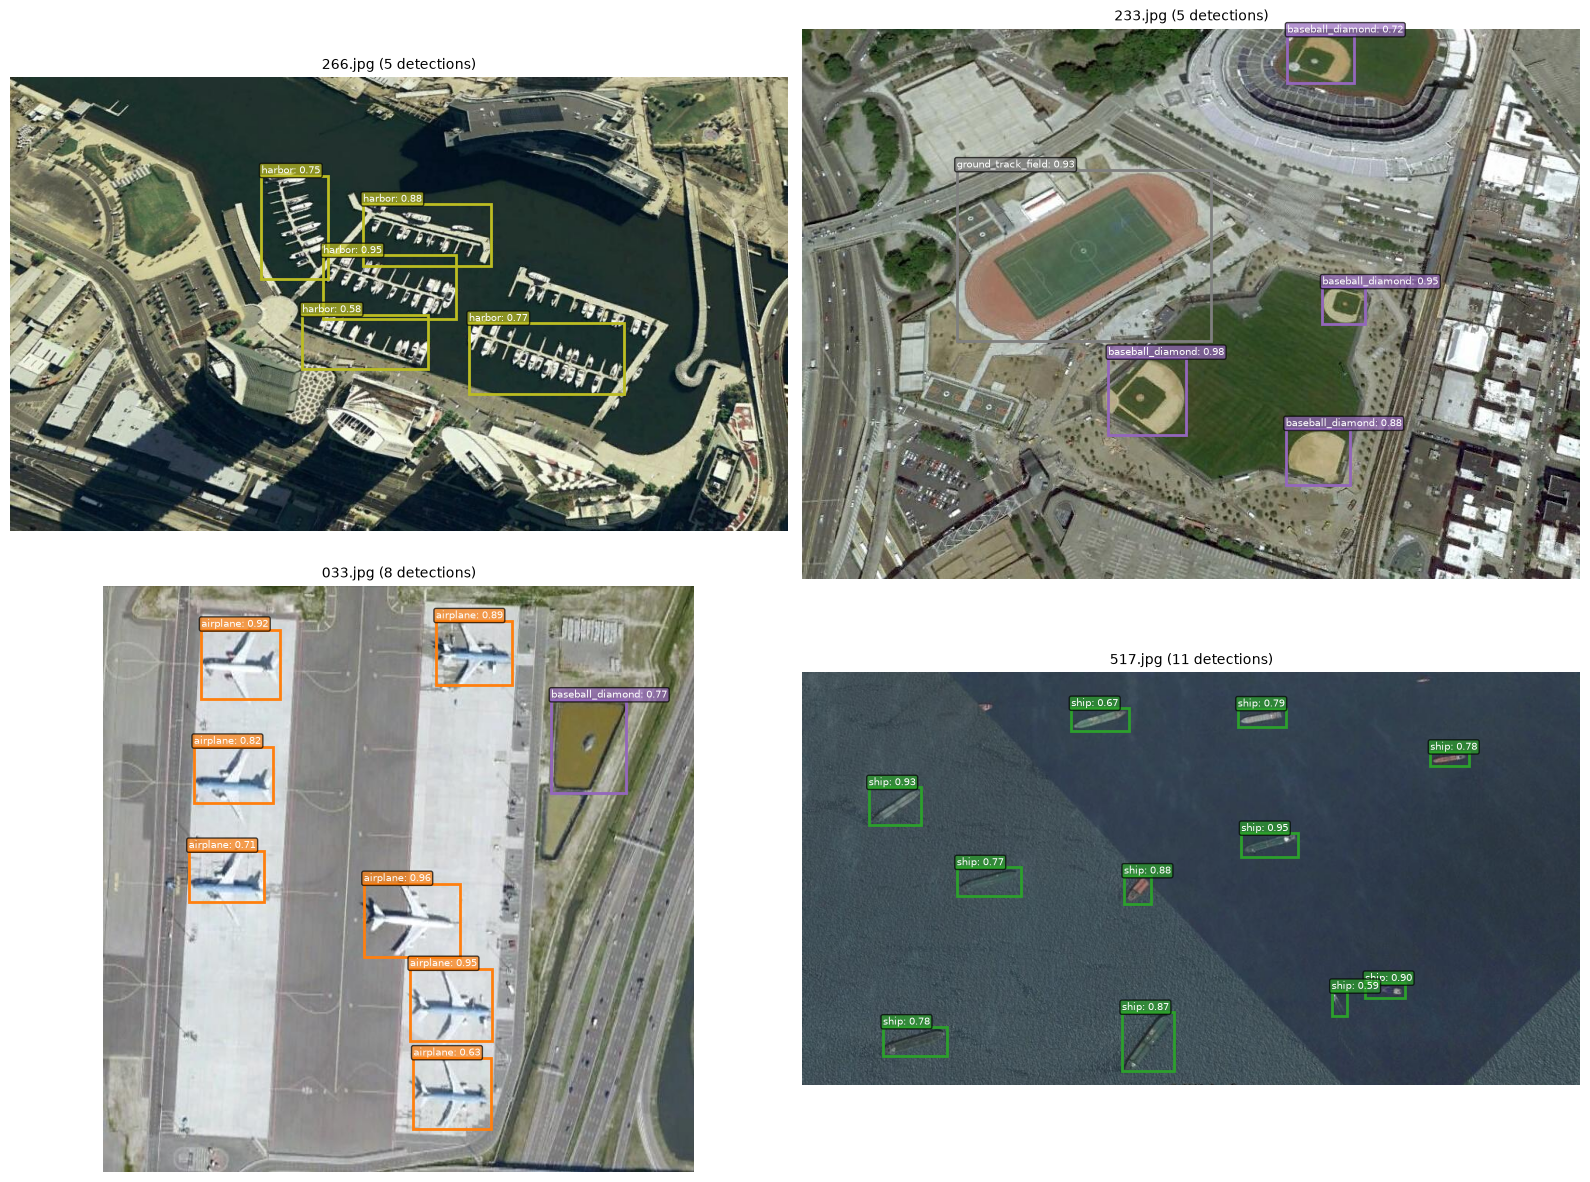

In [10]:
results = geoai.batch_multiclass_detection(
    image_paths=val_image_paths,
    output_dir="nwpu_batch_output",
    model_path=model_path,
    num_classes=splits["num_classes"],
    class_names=splits["class_names"],
    confidence_threshold=0.5,
    num_channels=3,
    figsize=(16, 12),
)

`batch_multiclass_detection()` repeats the same single-image workflow across a list of paths and produces a visualization grid, which is the practical way to scan more than a handful of images without writing your own loop.

Batch processing gives you a better sense of variation than one hand-picked image.

Look deliberately for:

- a strong example,
- a weak example,
- a dense scene,
- a sparse scene,
- different object sizes,
- different backgrounds.

### E. Inspect false positives & negatives

Looking across a batch of results, you will typically find both kinds of error alongside correct detections. A {term}`false positive <False Positive>` occurs when the model predicts an object that is not actually there, for example, a baseball diamond flagged over open water. These errors can be caused by visually similar background structures, shadows, unusual viewing conditions or insufficient variation in the training data.

A {term}`false negative <False Negative>` occurs when a real object is missed entirely, for example, one ship in a cluster left undetected. Possible causes include small object size, occlusion, unusual orientation, low contrast or too few representative examples in the training data.

These errors suggest different follow-up questions:

```text
false positive
     ↓
What background or feature confused the model?
     ↓
Could additional hard negative examples help?

false negative
     ↓
What made the object difficult to detect?
     ↓
Could improved labels or more representative training examples help?
```

Also check whether the **confidence threshold** contributes to the pattern. Lower thresholds usually retain more detections and can increase recall, but may also introduce more false positives. Higher thresholds remove uncertain detections and can improve precision, but may increase false negatives. The appropriate balance depends on your application: a screening workflow with later manual review may tolerate extra false positives, while automated object counting may require stronger control of them.

Neither error type is captured fully by an aggregate mAP score. You therefore need to inspect individual predictions and look for patterns across several images before deciding what should change.

```{tip}
Keep a short, informal log of the false positives and false negatives you spot during manual review. Note the class, scene conditions and confidence score where useful. Repeated patterns, such as small objects being missed or one background type repeatedly triggering false detections, provide useful evidence for adjusting your workflow and for discussing your project's limitations.
```

---

## 4. Python reactivation

`result_path, inference_time, detections = geoai.multiclass_detection(...)` unpacks a function's multiple return values into three separate variables in one line, the same tuple-unpacking pattern you may have used before for functions that return more than one result. The list comprehension building `val_image_paths` (`[os.path.join(...) for img in val_data["images"][:4]]`) combines a loop and a transformation into a single line; it is equivalent to a `for` loop that appends to an empty list, just more compact.

---

## 5. Common pitfalls

- **Leaving `confidence_threshold` at a default without checking whether it fits your use case.** A lower threshold surfaces more candidate objects for a counting task where missing objects is costly; a higher threshold reduces false alarms for a task where each detection triggers a follow-up action.
- **Choosing `window_size` and `overlap` without considering your object size.** If objects are larger than your window, they may be split across tiles in ways that hurt localization. Overlap should generally be at least as large as your biggest expected object.
- **Trusting batch results without spot-checking a few individually.** Batch inference is efficient, but the visual review in step D is still necessary; do not skip straight from a detection count to a project conclusion.
- **Confusing inference speed with model quality.** A fast inference time is convenient, not evidence that the detections are accurate.

---

## 6. Mini task

Using the single-image inference code above as a reference, predict what would happen to `len(detections)` if you changed `confidence_threshold` from `0.5` to `0.8`, and separately, what would happen if you changed it to `0.2`. You do not need to run the code, just reason through the direction of the change.

:::{dropdown} Sample solution
:class: note

Raising the threshold to `0.8` keeps only the model's most confident predictions, so `len(detections)` should decrease, likely cutting some real but lower-confidence objects along with genuine false positives. Lowering it to `0.2` keeps far more predictions, so `len(detections)` should increase substantially, almost certainly including more false positives along with any additional true detections. Neither threshold is "correct" in the abstract; the right choice depends on whether missed objects or false alarms are more costly for the specific project.

A compact experiment could follow this pattern:

```python
thresholds = [0.2, 0.5, 0.8]

for threshold in thresholds:
    output_path = f"detection_{threshold}.tif"

    _, _, detections = geoai.multiclass_detection(
        input_path=test_img_path,
        output_path=output_path,
        model_path=model_path,
        num_classes=splits["num_classes"],
        class_names=splits["class_names"],
        window_size=512,
        overlap=256,
        confidence_threshold=threshold,
        batch_size=4,
        num_channels=3,
    )

    print(
        f"Threshold {threshold}: "
        f"{len(detections)} detections"
    )
```

:::

---

## 7. Key takeaways

- `geoai`'s inference functions handle tiling and cross-tile non-maximum suppression automatically; you still choose the confidence threshold.
- Visualizing individual detections, not just counting them, is how you catch false positives and false negatives that an aggregate metric hides.
- `batch_multiclass_detection()` extends the same workflow across multiple images efficiently, but does not replace manual spot-checking.
- The confidence threshold is a project decision, not a fixed default, and should reflect whether false positives or false negatives are more costly for your specific use case.

---

:::{admonition} Optional: publishing and reusing models with Hugging Face Hub
:class: dropdown

Sharing a trained detector through the {term}`Hugging Face Hub` lets others run inference immediately, without access to your original training data or compute. This is optional, advanced material, useful if you plan to share a model publicly as part of your project, but it is not required for the core detection workflow.

Publishing requires a free Hugging Face account and a write-access token, set up once with `notebook_login()`:

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

`push_detector_to_hub()` uploads the trained weights and a configuration file (class names, number of classes, architecture) to a repository you specify:

In [ ]:
url = geoai.push_detector_to_hub(
    model_path=model_path,
    repo_id="your-username/nwpu-vhr10-fasterrcnn",
    model_name="fasterrcnn_resnet50_fpn_v2",
    num_classes=splits["num_classes"],
    class_names=splits["class_names"],
)

`predict_detector_from_hub()` then runs inference directly from a hosted model, without needing a local checkpoint or class list at all:

In [ ]:
result_path, inference_time, detections = geoai.predict_detector_from_hub(
    input_path=test_img_path,
    output_path="hub_detection.tif",
    repo_id="giswqs/nwpu-vhr10-fasterrcnn",
    confidence_threshold=0.5,
)

If you use this for your project, note the licensing and data-sharing implications of publishing a model trained on your own data before making a repository public.
:::

---

### Useful links

- [NWPU VHR-10 dataset](https://www.kaggle.com/datasets/larbisck/nwpu-vhr-10) - a collection of very high resolution remote sensing images of 10 object classes (1-airplane, 2-ship, 3-storage tank, 4-baseball diamond, 5-tennis court, 6-basketball court, 7-ground track field, 8-harbor, 9-bridge, 10-vehicle)